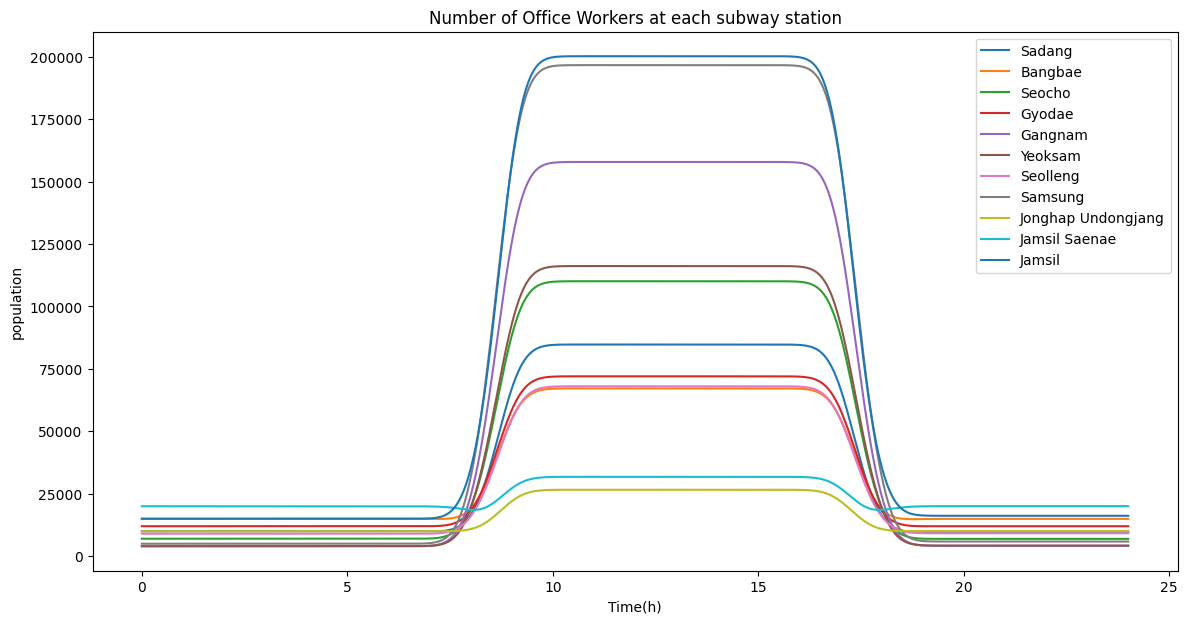

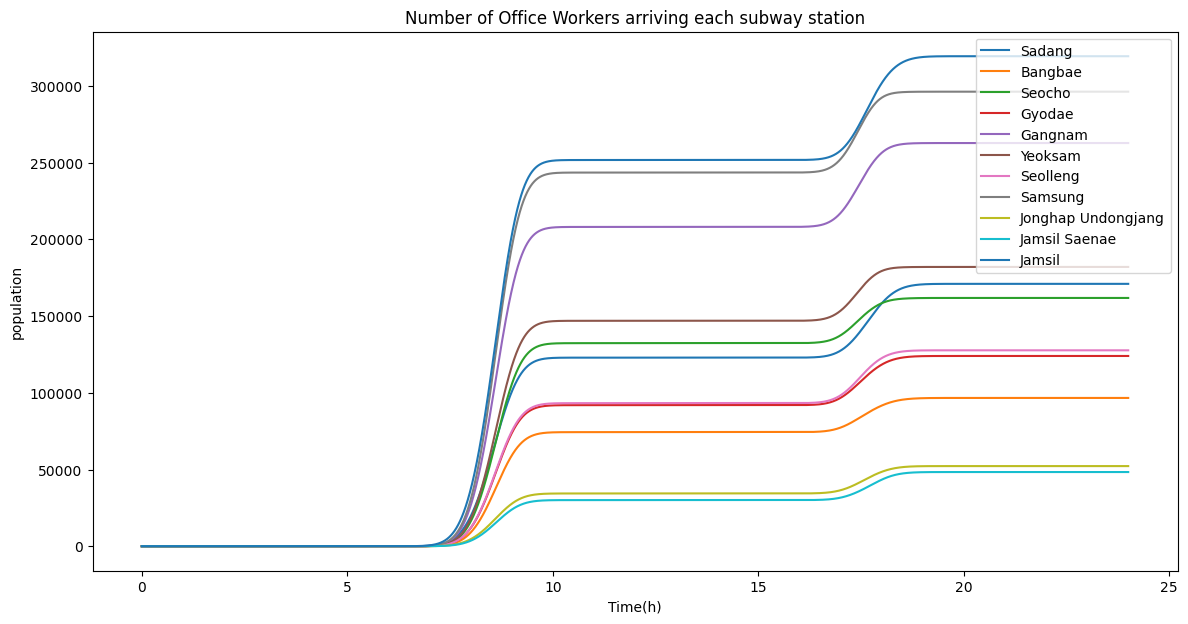

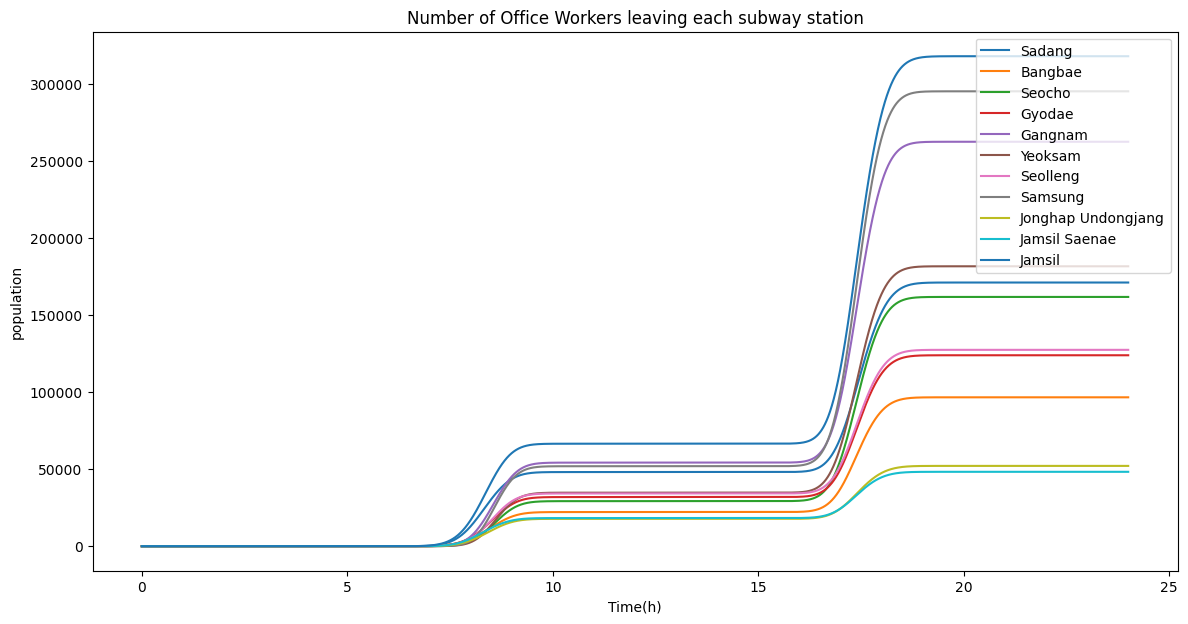

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 지하철에서 각 역에 거주하는 직장인 수와 각 역의 회사 비율을 알 때 시간에 따른 '각 역에 들어오는 직장인 수', '나가는 직장인 수', '각 역에 있는 총 직장인 수'를 제시해줌.

# 여기서 각 역에 있다는 것은 지하철을 기다리고 있을 수도 있고 그 역 부근의 회사에 있을 수도 있다는 것.
#단위 시간 당 출근하는 직장인 수는 정규분포를 따른다고 가정함. 정확히 8시 30분이 평균인 정규분포를 따라 직장인들이 회사가 있는 역에 도착함.
#단위 시간 당 퇴근하는 직장인 수는 정규분포를 따른다고 가정함. 정확히 17시 30분이 평균인 정규분포를 따라 직장인들이 회사가 있는 역에서 빠져나감.
#한편, 지하철의 배차 간격은 2분으로 일정하고 사람들이 많을 때 지하철의 이동속도가 느려지는 것을 미분방정식에 고려함.
#이러한 요소들을 고려하여 모든 사람이 정규분포를 따르도록 역에 도착하고, 역을 떠남.
#이를 통해 특정시간에 어느 역에서 직장인이 많이 탈지, 어느 시간 때에 어떻게 배차 간격을 늘려야 할지 파악할 수 있음.

name = ['Sadang','Bangbae','Seocho','Gyodae','Gangnam','Yeoksam','Seolleng','Samsung','Jonghap Undongjang','Jamsil Saenae','Jamsil'] #임의로 설정함.
N_0 = [10000,15000,7000,12000,4000,4000,9000,5000,10000,20000,15000] #각 역에 거주하는 직장인 수
N_out = [30000,0,0,7000,15000,0,10000,0,5000,0,30000] #외부 유입, 유출 직장인 수. 값이 0 이 아닌 역은 환승 역이다.
delta = [0.08,0.05,0.09,0.06,0.15,0.1,0.06,0.17,0.02,0.02,0.2] #각 역에 있는 회사 비율

#한 역에 사는 직장인의 직장은 회사 존재 비율에 따라 각 역에 균등하게 분포해 있다고 가정.
#즉, 사당에 사는 10000명의 직장인 중 800명은 이동하지 않고 사당역 부근에서 일하고 500명은 방배로 가며, 900명은 서초로 간다. 

num = len(N_0)
pi = np.pi

def normal_distrib_morning(t): #아침 시간을 기준으로 한 출근 정규 분포 
    std = 0.5
    return np.sqrt(1/(2*pi*std**2))*np.exp(-((t-8.5)**2)/(2*std**2))

def normal_distrib_afternoon(t): #저녁 시간을 기준으로 한 퇴근 정규 분포
    std = 0.5
    return np.sqrt(1/(2*pi*std**2))*np.exp(-((t-17.5)**2)/(2*std**2))

def dN_dt(n,N,t): #풀이할 미분 방정식의 우변
    f_in = 0
    f_out = 0
    k = 1/30
    for i in range(0,num):
        if i == n:
            pass
        else: 
            f_in += delta[n]*N_0[i]*normal_distrib_morning(t) # 아침 8시 30분에 출근 하는 사람이 가장 많도록 정규 분포 설정
             #아래와 같은 코드로 오후 5시 30분에 가장 많이 퇴근하도록 정규 분포, abs(n-i)*k로 지하철 이동 시간 고려, 1.2*N[i]로 사람 수가 많으면 이동 시간 늘어나도록 함.
            f_in += delta[i]*N_0[n]*normal_distrib_afternoon(t-1.2*N[i]*abs(n-i)*k/(((sum(N_0)+sum(N_out))/(num*2))))          
            #아래와 같은 코드로 오전 8시 30분에 가장 많이 출근하도록 정규 분포, abs(n-i)*k로 지하철 이동 시간 고려, 1.2*N[i]로 사람 수가 많으면 이동 시간 늘어나도록 함.
            f_out += delta[i]*N_0[n]*normal_distrib_morning(t+1.2*N[i]*abs(n-i)*k/(((sum(N_0)+sum(N_out))/(num*2))))  
            f_out += delta[n]*N_0[i]*normal_distrib_afternoon(t) # 오후 6시에 퇴근 하는 사람이 가장 많도록 정규 분포 설정
    #환승과 외부 유입 고려
    #환승 시간은 2분이며 정확히 퇴근시간과 출근 시간의 정규분포를 만족하기 위해 사람들이 움직인다고 가정한다.
    for j in range(0,num):
        if j == n:
            if N_out[j] ==0: # 환승역인지 아닌지 구분
                pass
            else:
                for a in range(0,num):
                    # 환승시간 2분을 1/30으로 고려해줌. 나머지 부분은 위쪽 코드와 거의 비슷, 이동시간 고려
                    f_in += delta[a]*N_out[j]*normal_distrib_morning(t+1.2*N[j]*abs(j-a)*k/(((sum(N_0)+sum(N_out))/(num*2)) +1/30))
                    f_in += N_out[j]*delta[a]*normal_distrib_afternoon(t-1.2*N[j]*abs(j-a)*k/(((sum(N_0)+sum(N_out))/(num*2))))
                    f_out += N_out[j]*delta[a]*normal_distrib_morning(t+1.2*N[j]*abs(j-a)*k/(((sum(N_0)+sum(N_out))/(num*2))))
                    f_out += delta[a]*N_out[j]*normal_distrib_afternoon(t-1.2*N[j]*abs(j-a)*k/(((sum(N_0)+sum(N_out))/(num*2))-1/30))
        else:
            for b in range(0,num):
                if b == n:
                    pass
                else:
                    f_in += delta[n]*N_out[j]*normal_distrib_morning(t)
                    f_out += delta[n]*N_out[j]*normal_distrib_afternoon(t)
                    
    return f_in-f_out, f_in, f_out

#RK4 알고리즘
t = 0
N = N_0
N_a = [0 for i in range(0,num)]
N_l = [0 for i in range(0,num)]

tpoints = [t]
Npoints = [[N_0[i]] for i in range(0,num)]
Narrpoints = [[0]for i in range(0,num)]
Nleapoints = [[0] for i in range(0,num)]

max_iter= 4800 #반복 횟수
dt = 0.005 #시간 단위는 '시(hours)'

for i in range(1,max_iter+1):
    N_array = np.array(N)
    for j in range(0,num):
        k1 = dN_dt(j,N_array,t)
        k2 = dN_dt(j,N_array+0.5*dt*k1[0],t+0.5*dt)
        k3 = dN_dt(j,N_array+0.5*dt*k2[0],t+0.5*dt)
        k4 = dN_dt(j,N_array+dt*k3[0],t+dt)

        N[j] += dt*(k1[0]+2*k2[0]+2*k3[0]+k4[0])/6 # 전체 직장인 수 변화
        N_a[j] += dt*(k1[1]+2*k2[1]+2*k3[1]+k4[1])/6 # 유입되는 직장인 수 변화
        N_l[j] += dt*(k1[2]+2*k2[2]+2*k3[2]+k4[2])/6 #유출되는 직장인 수 변화
        
        Npoints[j].append(N[j])
        Narrpoints[j].append(N_a[j])
        Nleapoints[j].append(N_l[j])
    
    t += dt
    tpoints.append(t)

#그래프 그리기 코드
plt.figure(1,figsize = (14,7))
for i in range(0,num):
    plt.plot(tpoints,Npoints[i],label = '%s'%name[i])
plt.xlabel('Time(h)')
plt.ylabel('population')
plt.title('Number of Office Workers at each subway station')
plt.legend(loc = 'upper right')

plt.figure(2,(14,7))
for i in range(0,num):
    plt.plot(tpoints,Narrpoints[i],label = '%s'%name[i])
plt.xlabel('Time(h)')
plt.ylabel('population')
plt.title('Number of Office Workers arriving each subway station')
plt.legend(loc = 'upper right')

plt.figure(3,figsize = (14,7))
for i in range(0,num):
    plt.plot(tpoints,Nleapoints[i],label = '%s'%name[i])
plt.xlabel('Time(h)')
plt.ylabel('population')
plt.title('Number of Office Workers leaving each subway station')
plt.legend(loc = 'upper right')
plt.show()